In [1]:
!pip install rdflib pandas requests python-dotenv openai langchain SPARQLWrapper

In [2]:
# Install required packages if not already installed
# !pip install rdflib pandas requests python-dotenv langchain openai

import rdflib
from rdflib import Namespace, URIRef, Literal, Graph
import re
import requests
import pandas as pd
import json
import os
from dotenv import load_dotenv
from langchain_core.prompts import PromptTemplate
from langchain.chains import LLMChain
from langchain_community.chat_models import ChatOpenAI
from SPARQLWrapper import SPARQLWrapper, JSON
import time


In [3]:
load_dotenv()
open_api_key = os.environ.get("OPENAI_API_KEY")

llm = ChatOpenAI(
    model="gpt-4o",  # or "gpt-4o-mini" if that's your specific plan
    temperature=0.1,
    api_key=open_api_key,
)



/tmp/ipykernel_80025/2761700150.py:4: LangChainDeprecationWarning: The class `ChatOpenAI` was deprecated in LangChain 0.0.10 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-openai package and should be used instead. To use it run `pip install -U :class:`~langchain-openai` and import as `from :class:`~langchain_openai import ChatOpenAI``.
  llm = ChatOpenAI(


In [4]:
# Wikidata endpoint
WIKIDATA_ENDPOINT = "https://query.wikidata.org/sparql"

# Namespaces
MO = Namespace("http://example.org/mo#")
EX = Namespace("http://example.org/billboard#")
TIME = Namespace("http://example.org/time#")
RDFS = Namespace("http://www.w3.org/2000/01/rdf-schema#")
RDF = Namespace("http://www.w3.org/1999/02/22-rdf-syntax-ns#")
OWL = Namespace("http://www.w3.org/2002/07/owl#")
XSD = Namespace("http://www.w3.org/2001/XMLSchema#")



# File paths
graph_path = "output/music_knowledge_graph.ttl"
mo_ontology = "ontologies/music_ontology.ttl"
bb_ontology = "ontologies/billboard.ttl"
time_ontology = "ontologies/time.ttl"


In [5]:
g = Graph()
print("Parsing ontologies and main graph...")
g.parse(mo_ontology, format="turtle")
g.parse(bb_ontology, format="turtle")
g.parse(time_ontology, format="turtle")
g.parse(graph_path, format="turtle")
print(f"Graph loaded with {len(g)} triples.")


Parsing ontologies and main graph...
Graph loaded with 368254 triples.


In [6]:
def load_graph(turtle_file):
    print(f"Loading graph from: {turtle_file}")
    graph = rdflib.Graph()
    graph.parse(turtle_file, format='turtle')
    return graph


In [21]:
import json

def query_artists_with_unknown_gender(graph, output_path="artists_with_unknown_gender.json"):
    print("Querying artists with unknown gender...")
    query = """
    PREFIX mo: <http://example.org/mo#>
    PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
    PREFIX ex: <http://example.org/artist/>

    SELECT DISTINCT ?artist ?artistName ?legalName ?dob
    WHERE {
      ?artist a mo:MusicArtist ;
              rdfs:label ?artistName .

      OPTIONAL { ?artist mo:legalName ?legalName. }
      OPTIONAL { ?artist mo:dateOfBirth ?dob. }

      FILTER NOT EXISTS {
        ?artist mo:hasGender ?gender .
        FILTER (
          ?gender = mo:gender_male || 
          ?gender = mo:gender_female || 
          ?gender = mo:gender_other
        )
      }
    }
    ORDER BY ?artistName
    """
    results = graph.query(query)
    print(f"Found {len(results)} artists with unknown gender.")
    
    unknown_gender_artists = []
    for row in results:
        unknown_gender_artists.append({
            "artist_label": str(row.artistName),
            "artist_uri": str(row.artist),  
            "legalName": str(row.legalName) if row.legalName else None,
            "dateOfBirth": str(row.dob) if row.dob else None
        })

    # Save to JSON
    with open(output_path, "w", encoding="utf-8") as f:
        json.dump(unknown_gender_artists, f, indent=2, ensure_ascii=False)
    print(f"Saved {len(unknown_gender_artists)} records to {output_path}")

    return unknown_gender_artists


In [9]:
def clean_artist_label(name):
    name = name.lower()
    name = re.sub(r'feat.*$', '', name)
    name = re.sub(r'\W+', ' ', name)
    return name.strip().title()


In [20]:
def wikidata_artist_query(artist_info):
    artist_label = clean_artist_label(artist_info["artist_label"])
    print(f"Searching Wikidata for: {artist_label}")

    query = f"""
    PREFIX wd: <http://www.wikidata.org/entity/>
    PREFIX wdt: <http://www.wikidata.org/prop/direct/>
    PREFIX wikibase: <http://wikiba.se/ontology#>
    PREFIX bd: <http://www.bigdata.com/rdf#>
    PREFIX mwapi: <https://www.mediawiki.org/ontology#API/>

    SELECT ?artist ?artistLabel ?birthName ?dob ?genderLabel WHERE {{
      SERVICE wikibase:mwapi {{
        bd:serviceParam wikibase:endpoint "www.wikidata.org";
                        wikibase:api "EntitySearch";
                        mwapi:search "{artist_label}";
                        mwapi:language "en".
        ?artist wikibase:apiOutputItem mwapi:item.
      }}

      ?artist wdt:P31 wd:Q5 .  # Instance of human
      OPTIONAL {{ ?artist wdt:P1477 ?birthName. }}
      OPTIONAL {{ ?artist wdt:P569 ?dob. }}
      OPTIONAL {{ ?artist wdt:P21 ?gender. }}
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    LIMIT 1
    """

    sparql = SPARQLWrapper(WIKIDATA_ENDPOINT)
    sparql.setQuery(query)
    sparql.setReturnFormat(JSON)
    try:
        result = sparql.query().convert()
        bindings = result.get("results", {}).get("bindings", [])
        if bindings:
            b = bindings[0]
            print("Wikidata info retrieved.")
            return {
                "artist": artist_label,
                "legalName": b.get("birthName", {}).get("value", None),
                "dateOfBirth": b.get("dob", {}).get("value", None),
                "retrievedGender": b.get("genderLabel", {}).get("value", "").lower() or "unknown"
            }
        else:
            print("No Wikidata match found.")
            return None
    except Exception as e:
        print(f"Error querying Wikidata for '{artist_label}': {e}")
        return None


In [11]:
prompt_template = PromptTemplate(
    input_variables=["artist", "retrievedGender", "artist_slug"],
    template="""
You are an RDF triple generator. Given the following data for an artist:
- Artist: {artist}
- Retrieved gender from Wikidata: {retrievedGender}

Mapping rules:
- If the retrieved gender is "male", generate the triple:
  <http://example.org/artist/{artist_slug}> mo:hasGender <http://example.org/mo#gender_male> .
- If it is "female", generate the triple:
  <http://example.org/artist/{artist_slug}> mo:hasGender <http://example.org/mo#gender_female> .
- Otherwise, generate the triple:
  <http://example.org/artist/{artist_slug}> mo:hasGender <http://example.org/mo#gender_unknown> .

Output exactly one RDF triple in Turtle syntax.
"""
)
chain = LLMChain(llm=llm, prompt=prompt_template)


/tmp/ipykernel_80025/1974829951.py:19: LangChainDeprecationWarning: The class `LLMChain` was deprecated in LangChain 0.1.17 and will be removed in 1.0. Use :meth:`~RunnableSequence, e.g., `prompt | llm`` instead.
  chain = LLMChain(llm=llm, prompt=prompt_template)


In [12]:
def update_missing_artist_info(turtle_file, delay=1.5):
    graph = load_graph(turtle_file)
    missing_artists = query_artists_with_unknown_gender(graph)

    final_updates = []
    for artist in missing_artists:
        print("=" * 40)
        print(f"Processing: {artist['artist_label']}")
        wikidata_info = wikidata_artist_query(artist)
        time.sleep(delay)  # 🔥 Throttle each request
        if wikidata_info:
            rdf_triple = generate_gender_triple(wikidata_info)
            final_updates.append({
                "artist": artist["artist_label"],
                "legalName": wikidata_info.get("legalName"),
                "dateOfBirth": wikidata_info.get("dateOfBirth"),
                "retrievedGender": wikidata_info.get("retrievedGender"),
                "rdfTriple": rdf_triple
            })
        else:
            print(f"No Wikidata info found for: {artist['artist_label']}")


In [13]:
def artist_to_slug(artist_name):
    slug = re.sub(r'\s+', '-', artist_name.strip().lower())
    slug = re.sub(r'[^a-z0-9\-]', '', slug)
    return slug


In [23]:
def generate_gender_triple(artist_info):
    artist_name = artist_info.get("artist")
    retrieved_gender = artist_info.get("retrievedGender") or "unknown"
    slug = artist_to_slug(artist_name)
    prompt_inputs = {
        "artist": artist_name,
        "retrievedGender": retrieved_gender,
        "artist_slug": slug
    }
    print(f"Generating RDF triple for {artist_name} with gender '{retrieved_gender}'...")
    triple = chain.run(prompt_inputs)
    print(f"Generated triple: {triple.strip()}")
    return triple.strip()


In [15]:
def update_missing_artist_info(turtle_file):
    graph = load_graph(turtle_file)
    missing_artists = query_artists_with_unknown_gender(graph)

    final_updates = []
    for artist in missing_artists:
        print("=" * 40)
        print(f"Processing: {artist['artist_label']}")
        wikidata_info = wikidata_artist_query(artist)
        if wikidata_info:
            rdf_triple = generate_gender_triple(wikidata_info)
            final_updates.append({
                "artist": artist["artist_label"],
                "artist_uri": artist["artist_uri"],
                "legalName": wikidata_info.get("legalName"),
                "dateOfBirth": wikidata_info.get("dateOfBirth"),
                "retrievedGender": wikidata_info.get("retrievedGender"),
                "sampleSong": wikidata_info.get("sampleSong"),
                "rdfTriple": rdf_triple
            })
        else:
            print(f"No Wikidata info found for: {artist['artist_label']}")
    
    df_updates = pd.DataFrame(final_updates)
    df_updates.to_csv("artists_gender_updates.csv", index=False, encoding="utf-8")
    print("Saved CSV output: artists_gender_updates.csv")

    with open("artists_gender_updates.json", "w", encoding="utf-8") as f:
        json.dump(final_updates, f, indent=2)
    print("Saved JSON output: artists_gender_updates.json")

    ttl_graph = rdflib.Graph()
    ttl_graph.bind("mo", MO)
    for update in final_updates:
        try:
            ttl_graph.parse(data=update["rdfTriple"], format="turtle")
        except Exception as e:
            print(f"Error parsing triple for {update['artist']}: {e}")
    ttl_graph.serialize("artists_gender_updates.ttl", format="turtle")
    print("Saved Turtle output: artists_gender_updates.ttl")

    return final_updates


In [22]:
# Run the full update pipeline
updates = update_missing_artist_info(graph_path)


Loading graph from: output/music_knowledge_graph.ttl
Querying artists with unknown gender...
Found 343 artists with unknown gender.
Saved 343 records to artists_with_unknown_gender.json
Processing: 2 Chains
Searching Wikidata for: 2 Chains
No Wikidata match found.
No Wikidata info found for: 2 Chains
Processing: 21 Savage and Metro Boomin
Searching Wikidata for: 21 Savage And Metro Boomin
No Wikidata match found.
No Wikidata info found for: 21 Savage and Metro Boomin
Processing: 2Cellos
Searching Wikidata for: 2Cellos
No Wikidata match found.
No Wikidata info found for: 2Cellos
Processing: 3OH!3
Searching Wikidata for: 3Oh 3
No Wikidata match found.
No Wikidata info found for: 3OH!3
Processing: 5 Seconds Of Summer
Searching Wikidata for: 5 Seconds Of Summer
No Wikidata match found.
No Wikidata info found for: 5 Seconds Of Summer
Processing: 6i
Searching Wikidata for: 6I
Wikidata info retrieved.
Generating RDF triple for 6I with gender 'male'...
Generated triple: ```turtle
<http://examp

Results

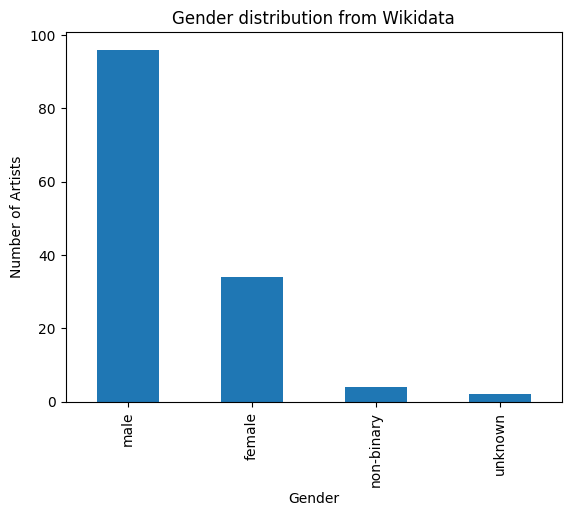

In [24]:
import matplotlib.pyplot as plt

df = pd.read_csv("artists_gender_updates.csv")
gender_counts = df["retrievedGender"].value_counts()

gender_counts.plot(kind="bar", title="Gender distribution from Wikidata")
plt.xlabel("Gender")
plt.ylabel("Number of Artists")
plt.show()


In [25]:
df = pd.read_csv("artists_gender_updates.csv")

print(f"Number of successfully updated artists: {len(df)}")

df.head()

✅ Number of successfully updated artists: 136


,artist,artist_uri,legalName,dateOfBirth,retrievedGender,sampleSong,rdfTriple
0,6i,http://example.org/mo#artist_6i_653c60,NaN,1989-07-08T00:00:00Z,male,NaN,```turtle\n<http://example.org/artist/6i> mo:h...
1,9ine,http://example.org/mo#artist_9ine_e6f6ef,Paulo Fernando Fazenda Manuel,1998-11-19T00:00:00Z,male,NaN,```turtle\n<http://example.org/artist/9ine> mo...
2,9ine feat Anuel AA,http://example.org/mo#artist_9ine_feat_anuel_a...,Paulo Fernando Fazenda Manuel,1998-11-19T00:00:00Z,male,NaN,```turtle\n<http://example.org/artist/9ine> mo...
3,@iHeartMemphis,http://example.org/mo#artist_iheartmemphis_57a2af,NaN,1993-01-25T00:00:00Z,male,NaN,```turtle\n<http://example.org/artist/iheartme...
4,A Boogie Wit Da Hoodie,http://example.org/mo#artist_a_boogie_wit_da_h...,Artist Julius DuBose,1995-12-06T00:00:00Z,male,NaN,```turtle\n<http://example.org/artist/a-boogie...
